# Projeto de Classificação de Dados – 2026.2
## Parte 2 – Qualidade do Vinho Verde Branco (8 pontos)
**Aluno:** Carlos José

**Contexto:** somos engenheiros de dados de uma vinícola. Queremos prever se um vinho é **Bom (1)** ou
**Regular (0)** só com os testes químicos de laboratório.

- Base: *Wine Quality – Vinho Verde Branco* (repositório UCI), 4.898 vinhos e 11 medidas físico-químicas.
- Regra do rótulo: nota **≥ 6 → Bom (1)**; nota **< 6 → Regular (0)**.

Etapas: **Fase 1** análise exploratória · **Fase 2** preparação · **Fase 3** escolha do classificador ·
**Fase 4** avaliação no conjunto de teste.

## 0. Bibliotecas

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, make_scorer, recall_score, roc_curve, roc_auc_score

# Classificadores vistos em aula
from sklearn.linear_model import LogisticRegression, Perceptron
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

sns.set_style('whitegrid')

## 1. Carregando a base
Comandos do enunciado. Se o site da UCI estiver fora do ar, usamos uma cópia idêntica no GitHub.

In [2]:
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/wine-quality/winequality-white.csv"
copia = "https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/winequality-white.csv"

try:
    dados = pd.read_csv(url, sep=';')
except Exception:
    print('UCI indisponível, usando a cópia do GitHub.')
    dados = pd.read_csv(copia, sep=';')

# Traduz os nomes das colunas para facilitar a leitura
dados.columns = ['acidez_fixa', 'acidez_volatil', 'acido_citrico', 'acucar_residual', 'cloretos',
                 'so2_livre', 'so2_total', 'densidade', 'pH', 'sulfatos', 'alcool', 'quality']

# Rótulo binário (regra do enunciado): 1 = Bom, 0 = Regular
dados['rotulo'] = np.where(dados['quality'] >= 6, 1, 0)

# X = medidas químicas; y = rótulo
X = dados.drop(columns=['quality', 'rotulo'])
y = dados['rotulo']

print('Vinhos:', X.shape[0], '| Atributos:', X.shape[1])
dados.head()

UCI indisponível, usando a cópia do GitHub.


Vinhos: 4898 | Atributos: 11


,acidez_fixa,acidez_volatil,acido_citrico,acucar_residual,cloretos,so2_livre,so2_total,densidade,pH,sulfatos,alcool,quality,rotulo
0,7.0,0.27,0.36,20.7,0.045,45.0,170.0,1.0010,3.00,0.45,8.8,6,1
1,6.3,0.30,0.34,1.6,0.049,14.0,132.0,0.9940,3.30,0.49,9.5,6,1
2,8.1,0.28,0.40,6.9,0.050,30.0,97.0,0.9951,3.26,0.44,10.1,6,1
3,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,1
4,7.2,0.23,0.32,8.5,0.058,47.0,186.0,0.9956,3.19,0.40,9.9,6,1


---
# FASE 1 – Análise descritiva e exploratória
### 1.1 Qualidade dos dados

In [3]:
print('Valores faltando:', dados.isnull().sum().sum())
print('Linhas repetidas:', dados.duplicated().sum())

Valores faltando: 0
Linhas repetidas: 937


> Não há valores faltando. As linhas repetidas foram **mantidas**: são vinhos diferentes que tiveram as mesmas
> medições, e removê-las mudaria a proporção real dos dados.

### 1.2 Notas originais e classes

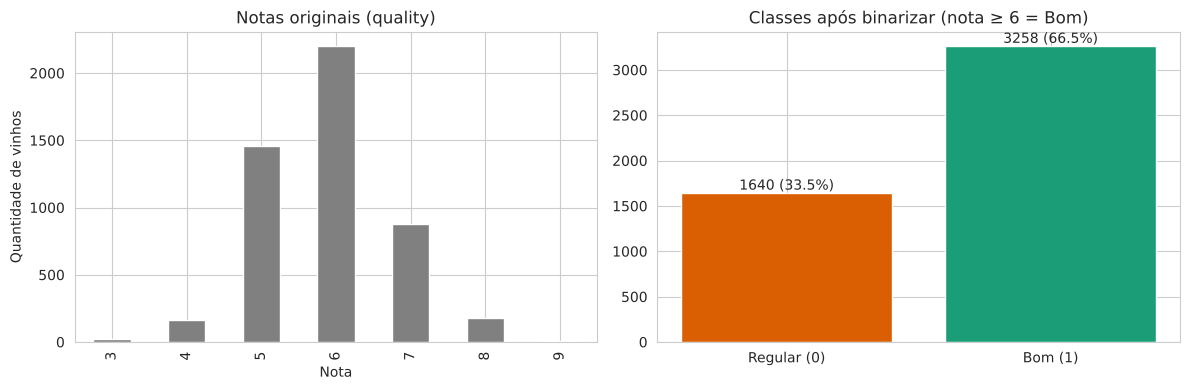

In [4]:
fig, eixos = plt.subplots(1, 2, figsize=(12, 4))

dados['quality'].value_counts().sort_index().plot(kind='bar', color='gray', ax=eixos[0])
eixos[0].set_title('Notas originais (quality)')
eixos[0].set_xlabel('Nota')
eixos[0].set_ylabel('Quantidade de vinhos')

contagem = y.value_counts().sort_index()
eixos[1].bar(['Regular (0)', 'Bom (1)'], contagem, color=['#d95f02', '#1b9e77'])
for i, v in enumerate(contagem):
    eixos[1].text(i, v + 40, f'{v} ({v / len(y):.1%})', ha='center')
eixos[1].set_title('Classes após binarizar (nota ≥ 6 = Bom)')

plt.tight_layout()
plt.show()

> A base é **desbalanceada**: cerca de 2/3 dos vinhos são "Bom". Um modelo que chutasse sempre "Bom" já
> teria ~66,5% de acurácia. Por isso olhamos também **sensibilidade** e **especificidade**.

### 1.3 Estatísticas descritivas (média, mediana e desvio padrão)

In [5]:
resumo = pd.DataFrame({
    'media':         X.mean(),
    'mediana':       X.median(),
    'desvio_padrao': X.std(),
    'minimo':        X.min(),
    'maximo':        X.max(),
    'correlacao_com_rotulo': X.corrwith(y),
})
display(resumo.round(4))

,media,mediana,desvio_padrao,minimo,maximo,correlacao_com_rotulo
acidez_fixa,6.8548,6.8000,0.8439,3.8000,14.200,-0.0897
acidez_volatil,0.2782,0.2600,0.1008,0.0800,1.100,-0.2254
acido_citrico,0.3342,0.3200,0.1210,0.0000,1.660,-0.0007
acucar_residual,6.3914,5.2000,5.0721,0.6000,65.800,-0.0928
cloretos,0.0458,0.0430,0.0218,0.0090,0.346,-0.1839
so2_livre,35.3081,34.0000,17.0071,2.0000,289.000,-0.0013
so2_total,138.3607,134.0000,42.4981,9.0000,440.000,-0.1709
densidade,0.9940,0.9937,0.0030,0.9871,1.039,-0.2687
pH,3.1883,3.1800,0.1510,2.7200,3.820,0.0837
sulfatos,0.4898,0.4700,0.1141,0.2200,1.080,0.0519


In [6]:
# Média de cada atributo separada por classe
media_por_classe = dados.groupby('rotulo')[list(X.columns)].mean().T
media_por_classe.columns = ['Regular (0)', 'Bom (1)']
media_por_classe['diferenca_%'] = (media_por_classe['Bom (1)'] / media_por_classe['Regular (0)'] - 1) * 100
display(media_por_classe.round(4))

,Regular (0),Bom (1),diferenca_%
acidez_fixa,6.9615,6.8011,-2.3050
acidez_volatil,0.3103,0.2621,-15.5171
acido_citrico,0.3343,0.3341,-0.0537
acucar_residual,7.0545,6.0577,-14.1300
cloretos,0.0514,0.0429,-16.5537
so2_livre,35.3387,35.2927,-0.1303
so2_total,148.5979,133.2075,-10.3571
densidade,0.9952,0.9935,-0.1711
pH,3.1705,3.1972,0.8445
sulfatos,0.4815,0.4940,2.6042


> As escalas são muito diferentes (densidade ≈ 0,99 e SO₂ total ≈ 138), o que pede **padronização** na Fase 2.
> Em média, os vinhos bons têm **mais álcool** e **menos densidade, cloretos, acidez volátil e SO₂ total**.

### 1.4 Boxplots por classe

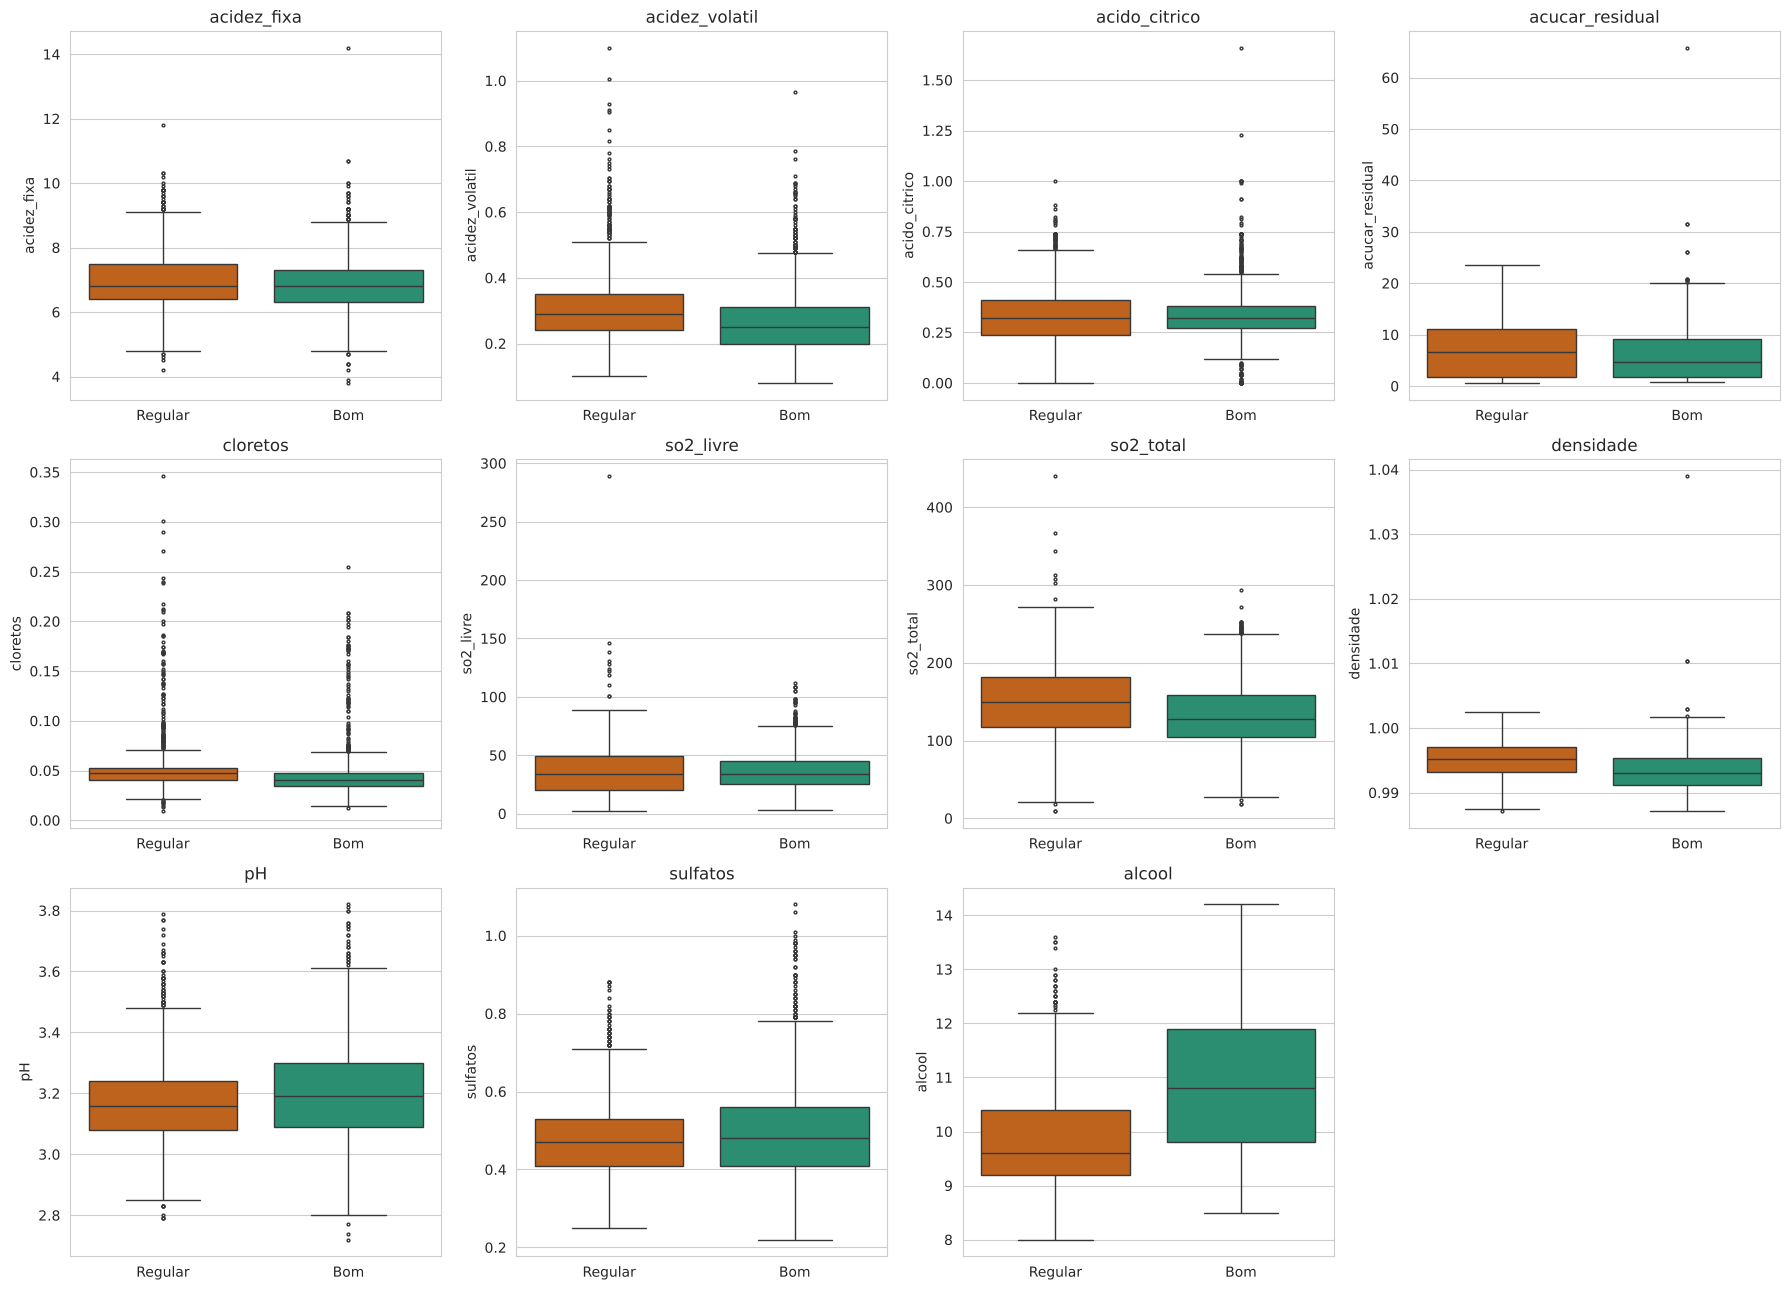

In [7]:
dados['classe'] = dados['rotulo'].map({0: 'Regular', 1: 'Bom'})
cores = {'Regular': '#d95f02', 'Bom': '#1b9e77'}

fig, eixos = plt.subplots(3, 4, figsize=(18, 13))
eixos = eixos.flatten()
for i, coluna in enumerate(X.columns):
    sns.boxplot(data=dados, x='classe', y=coluna, hue='classe', order=['Regular', 'Bom'],
                palette=cores, legend=False, ax=eixos[i], fliersize=2)
    eixos[i].set_title(coluna)
    eixos[i].set_xlabel('')
eixos[-1].axis('off')
plt.tight_layout()
plt.show()

### 1.5 Histogramas por classe

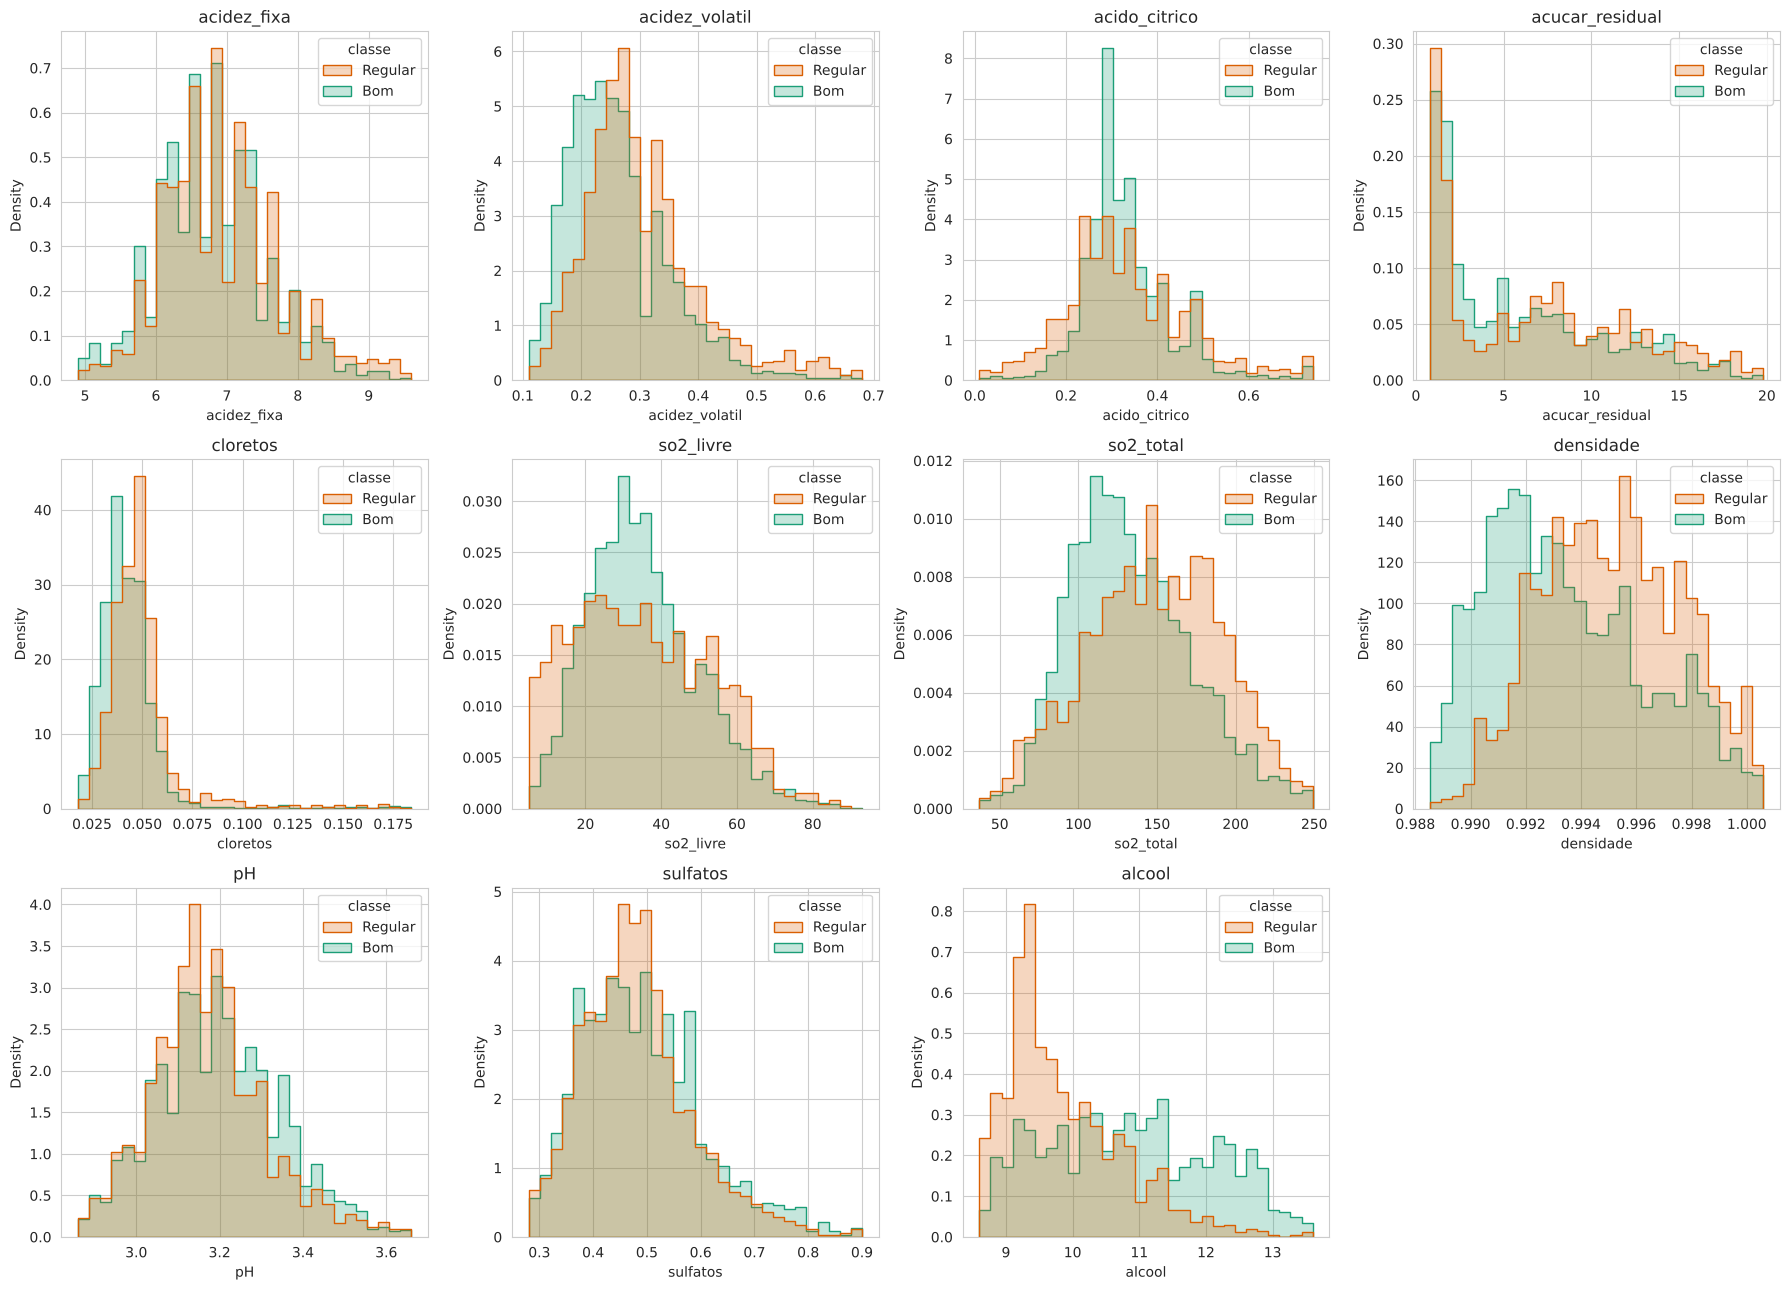

In [8]:
fig, eixos = plt.subplots(3, 4, figsize=(18, 13))
eixos = eixos.flatten()
for i, coluna in enumerate(X.columns):
    # corta 1% dos valores mais extremos só para o gráfico ficar legível
    limite_baixo, limite_alto = dados[coluna].quantile([0.005, 0.995])
    parte = dados[(dados[coluna] >= limite_baixo) & (dados[coluna] <= limite_alto)]
    sns.histplot(data=parte, x=coluna, hue='classe', hue_order=['Regular', 'Bom'], palette=cores,
                 stat='density', common_norm=False, element='step', bins=30, ax=eixos[i])
    eixos[i].set_title(coluna)
eixos[-1].axis('off')
plt.tight_layout()
plt.show()

> As distribuições das duas classes **se sobrepõem em quase todos os atributos**. A diferença mais clara está
> no **álcool**, seguida da **densidade**. Ácido cítrico, SO₂ livre, sulfatos e pH quase não mudam entre as classes.

### 1.6 Análise de sobreposição – correlação

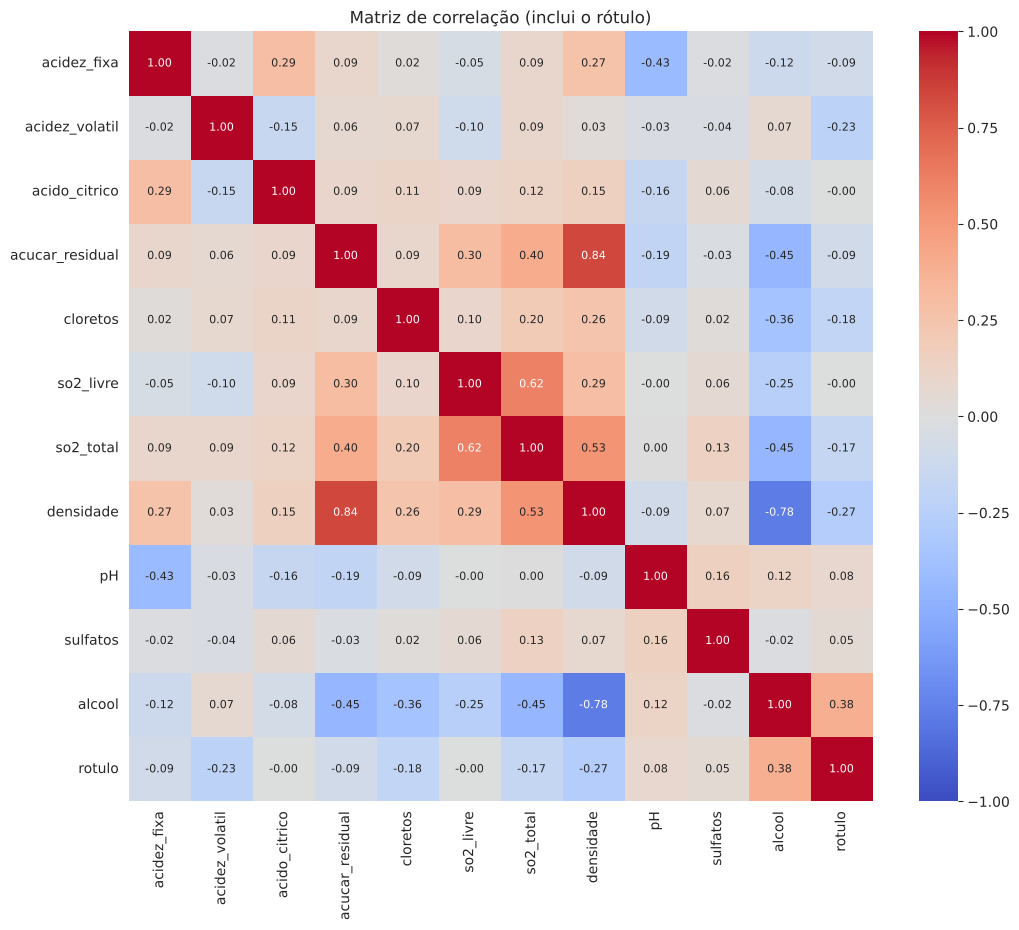

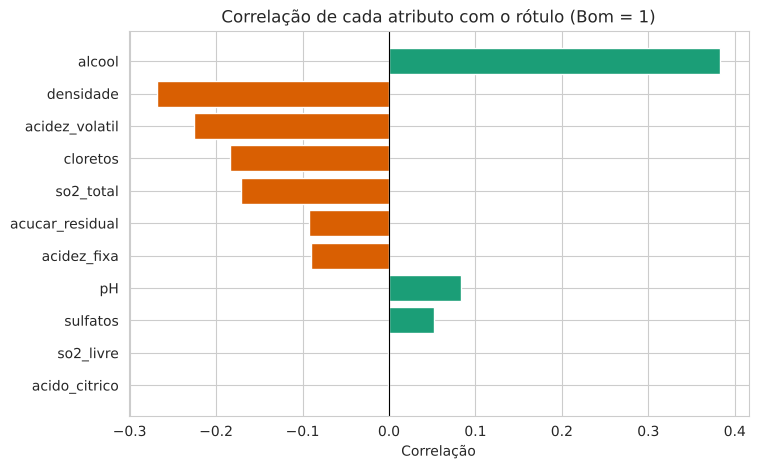

In [9]:
correlacao = dados[list(X.columns) + ['rotulo']].corr()

plt.figure(figsize=(12, 10))
sns.heatmap(correlacao, vmin=-1, vmax=1, cmap='coolwarm', annot=True, fmt='.2f', annot_kws={'size': 8})
plt.title('Matriz de correlação (inclui o rótulo)')
plt.show()

# Correlação de cada atributo com o rótulo, da maior para a menor (em valor absoluto)
corr_rotulo = X.corrwith(y).sort_values(key=abs)
plt.figure(figsize=(8, 5))
plt.barh(corr_rotulo.index, corr_rotulo, color=['#1b9e77' if v > 0 else '#d95f02' for v in corr_rotulo])
plt.axvline(0, color='black', linewidth=0.8)
plt.title('Correlação de cada atributo com o rótulo (Bom = 1)')
plt.xlabel('Correlação')
plt.show()

### 1.7 Análise de sobreposição – gráficos de dispersão

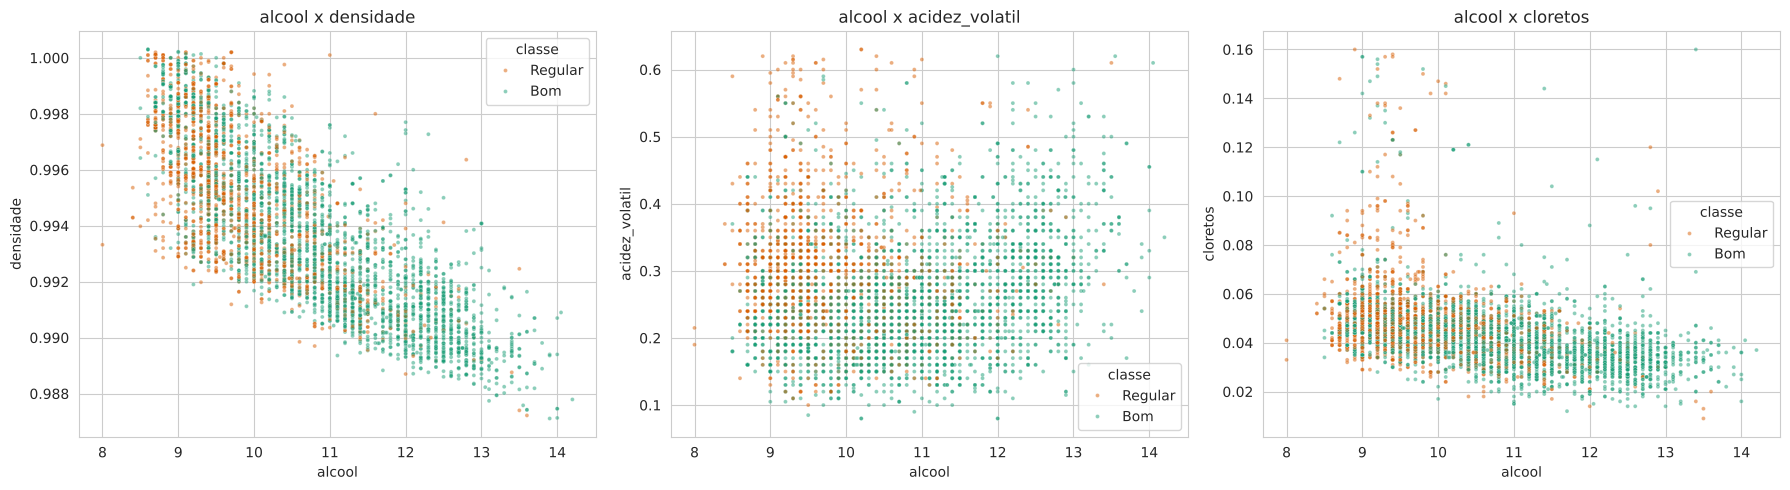

In [10]:
# Álcool (a melhor candidata) contra as próximas da lista
pares = [('alcool', 'densidade'), ('alcool', 'acidez_volatil'), ('alcool', 'cloretos')]

fig, eixos = plt.subplots(1, 3, figsize=(18, 5))
for eixo, (vx, vy) in zip(eixos, pares):
    parte = dados[dados[vy] <= dados[vy].quantile(0.99)]   # tira 1% extremo só para visualizar
    sns.scatterplot(data=parte, x=vx, y=vy, hue='classe', hue_order=['Regular', 'Bom'],
                    palette=cores, s=8, alpha=0.5, ax=eixo)
    eixo.set_title(f'{vx} x {vy}')
plt.tight_layout()
plt.show()

**Conclusão da Fase 1**
- Os pontos "Bom" e "Regular" aparecem **misturados**: há uma tendência (mais álcool e menos densidade/acidez
  volátil/cloretos favorecem "Bom"), mas a fronteira entre as classes **não é limpa nem reta**.
- **Melhores candidatas:** álcool (+0,38), densidade (−0,27), acidez volátil (−0,23), cloretos (−0,18) e SO₂ total (−0,17).
- A densidade repete parte da informação do álcool (−0,78) e do açúcar residual (+0,84).
- Por isso esperamos que modelos que traçam **fronteiras curvas** (SVM com kernel RBF e Rede Neural MLP) se saiam melhor.

---
# FASE 2 – Preparação dos dados
### 2.1 random_state a partir do primeiro nome
Regra do enunciado: A=1, B=2, ..., Z=26 e somamos as letras do primeiro nome.

In [11]:
def soma_letras(nome):
    """Soma o peso das letras (a=1 ... z=26)."""
    return sum(ord(letra) - ord('a') + 1 for letra in nome.lower() if letra.isalpha())

primeiro_nome = 'carlos'
SEMENTE = soma_letras(primeiro_nome)

print(' + '.join(f'{l.upper()}({ord(l) - 96})' for l in primeiro_nome), '=', SEMENTE)
print('random_state =', SEMENTE)

C(3) + A(1) + R(18) + L(12) + O(15) + S(19) = 68
random_state = 68


### 2.2 Separação treino / teste (80% / 20%, estratificada)
`stratify=y` mantém a mesma proporção de Bom/Regular nos dois grupos.

In [12]:
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEMENTE)

tabela_divisao = pd.DataFrame({
    'vinhos':      [len(y), len(y_treino), len(y_teste)],
    'Regular (0)': [f'{(g == 0).mean():.1%}' for g in (y, y_treino, y_teste)],
    'Bom (1)':     [f'{(g == 1).mean():.1%}' for g in (y, y_treino, y_teste)],
}, index=['Base completa', 'Treino (80%)', 'Teste (20%)'])
display(tabela_divisao)

,vinhos,Regular (0),Bom (1)
Base completa,4898,33.5%,66.5%
Treino (80%),3918,33.5%,66.5%
Teste (20%),980,33.5%,66.5%


### 2.3 Padronização
Usamos `StandardScaler` (média 0 e desvio 1) **dentro de um Pipeline**, junto com o classificador.
Assim, em cada rodada da validação cruzada, a média e o desvio são calculados **só com os dados de treino**
daquela rodada – o teste nunca "vaza" para o treino.

In [13]:
# Exemplo: antes e depois da padronização (só para visualizar)
exemplo = pd.DataFrame(StandardScaler().fit_transform(X_treino), columns=X.columns)
display(pd.DataFrame({'media_antes': X_treino.mean(), 'desvio_antes': X_treino.std(),
                      'media_depois': exemplo.mean(), 'desvio_depois': exemplo.std()}).round(3))

,media_antes,desvio_antes,media_depois,desvio_depois
acidez_fixa,6.855,0.838,0.0,1.0
acidez_volatil,0.279,0.103,0.0,1.0
acido_citrico,0.335,0.123,-0.0,1.0
acucar_residual,6.396,5.098,-0.0,1.0
cloretos,0.046,0.022,-0.0,1.0
so2_livre,35.244,16.964,0.0,1.0
so2_total,138.580,42.364,0.0,1.0
densidade,0.994,0.003,0.0,1.0
pH,3.186,0.150,-0.0,1.0
sulfatos,0.490,0.114,-0.0,1.0


**Justificativas da Fase 2**
- **80/20:** 3.918 vinhos para aprender e 980 guardados como "prova final", usados só na Fase 4.
- **stratify=y:** garante 33,5% / 66,5% no treino e no teste; sem isso o teste poderia ter poucos vinhos regulares.
- **random_state = 68** na divisão, na validação cruzada e em todos os classificadores: resultados reproduzíveis.
- **Padronização:** necessária para Regressão Logística, SVM e Redes Neurais, que usam distâncias e somas com pesos
  e seriam dominadas pelos atributos de valores grandes (SO₂). Para a Árvore não é necessária, mas não atrapalha.
- **Todos os 11 atributos mantidos:** mesmo com sobreposição, cada um contribui com um pouco de informação.

---
# FASE 3 – Escolha e treinamento do classificador
Avaliamos os classificadores vistos em aula com **validação cruzada de 5 partes, só no grupo de treino**.
Para cada um testamos algumas configurações (busca em grade, `GridSearchCV`, como na aula 11) e guardamos a de
**maior acurácia média**.

Métricas (classe positiva = Bom):
- **Acurácia** = acertos / total
- **Sensibilidade** = VP / (VP + FN) → dos vinhos bons, quantos o modelo reconheceu
- **Especificidade** = VN / (VN + FP) → dos vinhos regulares, quantos o modelo reconheceu

In [14]:
# Métricas que a validação cruzada vai calcular
metricas = {
    'acuracia':       'accuracy',
    'sensibilidade':  'recall',                               # acerto na classe 1 (Bom)
    'especificidade': make_scorer(recall_score, pos_label=0),  # acerto na classe 0 (Regular)
    'precisao':       'precision',
    'f1':             'f1',
}

def com_padronizacao(modelo):
    """Junta padronização + classificador em um único passo."""
    return Pipeline([('padronizar', StandardScaler()), ('modelo', modelo)])

# Cada item: (modelo, configurações a testar). 'modelo__x' = parâmetro x do classificador.
classificadores = {
    'Regressão Logística': (
        com_padronizacao(LogisticRegression(max_iter=5000, random_state=SEMENTE)),
        {'modelo__C': [0.1, 1, 10]}),

    'Árvore de Decisão': (
        com_padronizacao(DecisionTreeClassifier(random_state=SEMENTE)),
        {'modelo__criterion': ['gini', 'entropy'],
         'modelo__max_depth': [4, 8, 12, None]}),

    'SVM': (
        com_padronizacao(SVC(random_state=SEMENTE)),
        {'modelo__kernel': ['linear', 'poly', 'rbf', 'sigmoid'],
         'modelo__C': [0.1, 1, 10]}),

    'Perceptron': (
        com_padronizacao(Perceptron(max_iter=4000, random_state=SEMENTE)),
        {'modelo__eta0': [0.001, 0.01, 0.1]}),

    'Rede Neural MLP': (
        com_padronizacao(MLPClassifier(max_iter=2000, random_state=SEMENTE)),
        {'modelo__hidden_layer_sizes': [(10, 10), (50, 25)],
         'modelo__activation': ['tanh', 'relu']}),
}

divisao = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMENTE)

In [15]:
# Roda a busca em cada classificador (pode levar 1 a 3 minutos no Colab)
buscas = {}
for nome, (modelo, opcoes) in classificadores.items():
    busca = GridSearchCV(modelo, opcoes, scoring=metricas, refit='acuracia', cv=divisao, n_jobs=-1)
    busca.fit(X_treino, y_treino)
    buscas[nome] = busca
    print(f'{nome:20s} melhor configuração: {busca.best_params_}')

Regressão Logística  melhor configuração: {'modelo__C': 10}


Árvore de Decisão    melhor configuração: {'modelo__criterion': 'entropy', 'modelo__max_depth': None}


SVM                  melhor configuração: {'modelo__C': 10, 'modelo__kernel': 'rbf'}
Perceptron           melhor configuração: {'modelo__eta0': 0.001}


Rede Neural MLP      melhor configuração: {'modelo__activation': 'tanh', 'modelo__hidden_layer_sizes': (50, 25)}


### 3.1 Tabela comparativa (média ± desvio das 5 partes)

In [16]:
def resultado_da_validacao(busca):
    """Pega média e desvio de cada métrica na melhor configuração."""
    i = busca.best_index_
    r = busca.cv_results_
    return {m: (r[f'mean_test_{m}'][i], r[f'std_test_{m}'][i]) for m in metricas}

validacao = {nome: resultado_da_validacao(b) for nome, b in buscas.items()}

# Ordena pela acurácia média
ordem = sorted(validacao, key=lambda n: validacao[n]['acuracia'][0], reverse=True)
tabela_fase3 = pd.DataFrame({n: {m: f'{validacao[n][m][0]:.3f} ± {validacao[n][m][1]:.3f}' for m in metricas}
                             for n in ordem})
tabela_fase3.loc['melhor configuração'] = [str({k.replace('modelo__', ''): v
                                               for k, v in buscas[n].best_params_.items()}) for n in ordem]
display(tabela_fase3)

,SVM,Rede Neural MLP,Árvore de Decisão,Regressão Logística,Perceptron
acuracia,0.789 ± 0.016,0.776 ± 0.016,0.773 ± 0.010,0.747 ± 0.007,0.684 ± 0.033
sensibilidade,0.864 ± 0.015,0.833 ± 0.024,0.837 ± 0.020,0.874 ± 0.012,0.690 ± 0.062
especificidade,0.641 ± 0.034,0.662 ± 0.022,0.646 ± 0.020,0.495 ± 0.023,0.673 ± 0.072
precisao,0.827 ± 0.014,0.831 ± 0.009,0.824 ± 0.006,0.775 ± 0.007,0.809 ± 0.027
f1,0.845 ± 0.012,0.832 ± 0.014,0.831 ± 0.009,0.821 ± 0.005,0.742 ± 0.037
melhor configuração,"{'C': 10, 'kernel': 'rbf'}","{'activation': 'tanh', 'hidden_layer_sizes': (...","{'criterion': 'entropy', 'max_depth': None}",{'C': 10},{'eta0': 0.001}


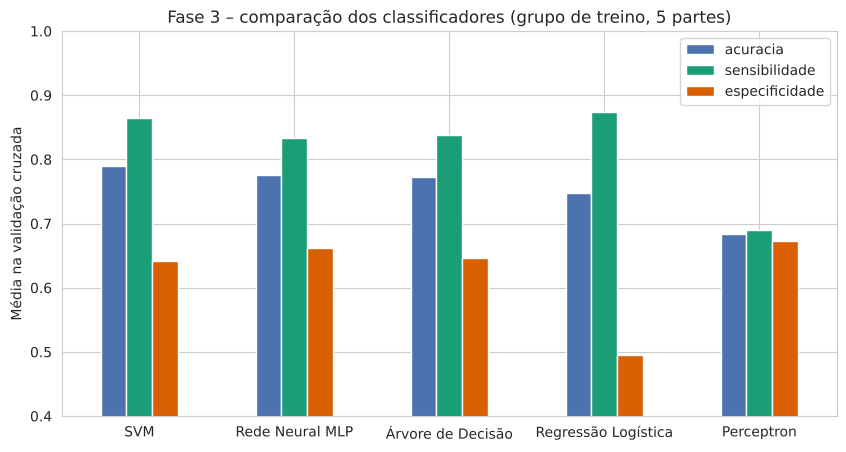

In [17]:
# Gráfico: acurácia, sensibilidade e especificidade de cada classificador
grafico = pd.DataFrame({n: {m: validacao[n][m][0] for m in ['acuracia', 'sensibilidade', 'especificidade']}
                        for n in ordem}).T
grafico.plot(kind='bar', figsize=(10, 5), color=['#4c72b0', '#1b9e77', '#d95f02'])
plt.ylim(0.4, 1.0)
plt.ylabel('Média na validação cruzada')
plt.title('Fase 3 – comparação dos classificadores (grupo de treino, 5 partes)')
plt.xticks(rotation=0)
plt.show()

### 3.2 Detalhe do SVM: qual kernel funcionou melhor?

In [18]:
r = pd.DataFrame(buscas['SVM'].cv_results_)
r['kernel'] = r['param_modelo__kernel']
r['C'] = r['param_modelo__C']
melhores_kernel = r.loc[r.groupby('kernel')['mean_test_acuracia'].idxmax(),
                        ['kernel', 'C', 'mean_test_acuracia', 'mean_test_sensibilidade', 'mean_test_especificidade']]
melhores_kernel.columns = ['kernel', 'melhor C', 'acuracia', 'sensibilidade', 'especificidade']
display(melhores_kernel.sort_values('acuracia', ascending=False).round(3))

,kernel,melhor C,acuracia,sensibilidade,especificidade
10,rbf,10.0,0.789,0.864,0.641
0,linear,0.1,0.750,0.889,0.473
9,poly,10.0,0.745,0.898,0.441
3,sigmoid,0.1,0.704,0.871,0.370


> O kernel **RBF** (curvo) ganha do **linear**, principalmente na especificidade. Isso confirma a Fase 1:
> as classes se sobrepõem e não dão para separar com uma reta.

### 3.3 Classificador escolhido

In [19]:
nome_escolhido = ordem[0]
modelo_escolhido = buscas[nome_escolhido].best_estimator_
print('Escolhido:', nome_escolhido, buscas[nome_escolhido].best_params_)
print(f"Acurácia média na validação: {validacao[nome_escolhido]['acuracia'][0]:.3f}")

Escolhido: SVM {'modelo__C': 10, 'modelo__kernel': 'rbf'}
Acurácia média na validação: 0.789


**Justificativa da escolha**
- O **SVM com kernel RBF (C = 10)** teve a **maior acurácia** e o **maior F1** na validação cruzada, com
  sensibilidade alta e especificidade razoável.
- A **Rede Neural MLP** ficou muito perto e teve especificidade um pouco melhor, mas acurácia e F1 menores e treino mais lento.
- A **Árvore de Decisão** ficou no meio; a melhor foi a de profundidade livre, que tende a decorar o treino.
- Os modelos **lineares** foram os piores: a Regressão Logística reconhece mal os regulares (especificidade baixa)
  e o Perceptron simples fica perto do chute "sempre Bom".
- Isso bate com a teoria: com classes sobrepostas de forma não linear, os modelos de fronteira curva vencem.

---
# FASE 4 – Avaliação no conjunto de teste
O modelo escolhido é treinado com **todo o grupo de treino** e testado nos **980 vinhos** que não participaram
de nenhuma etapa anterior.

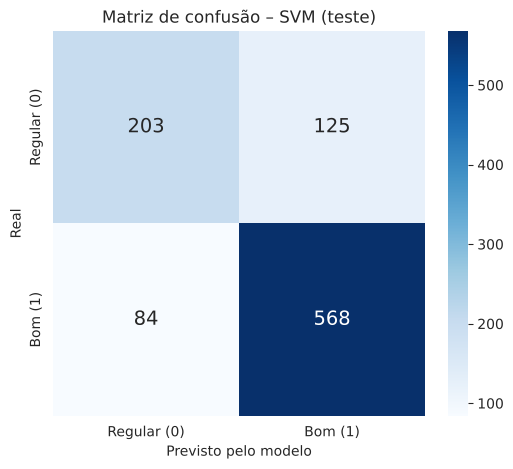

VP = 568 | VN = 203 | FP = 125 | FN = 84


In [20]:
modelo_escolhido.fit(X_treino, y_treino)
y_previsto = modelo_escolhido.predict(X_teste)

matriz = confusion_matrix(y_teste, y_previsto)
VN, FP, FN, VP = matriz.ravel()     # ordem do sklearn para classes 0 e 1

plt.figure(figsize=(6, 5))
sns.heatmap(matriz, annot=True, fmt='d', cmap='Blues', annot_kws={'size': 14},
            xticklabels=['Regular (0)', 'Bom (1)'], yticklabels=['Regular (0)', 'Bom (1)'])
plt.title(f'Matriz de confusão – {nome_escolhido} (teste)')
plt.xlabel('Previsto pelo modelo')
plt.ylabel('Real')
plt.show()

print(f'VP = {VP} | VN = {VN} | FP = {FP} | FN = {FN}')

### 4.1 Métricas calculadas com as fórmulas do enunciado

In [21]:
acuracia       = (VP + VN) / (VP + VN + FP + FN)
precisao       = VP / (VP + FP)
sensibilidade  = VP / (VP + FN)
especificidade = VN / (VN + FP)
f1             = 2 * precisao * sensibilidade / (precisao + sensibilidade)

teste = {'acuracia': acuracia, 'precisao': precisao, 'sensibilidade': sensibilidade,
         'especificidade': especificidade, 'f1': f1}
formulas = {'acuracia':       f'(VP+VN)/(VP+VN+FP+FN) = {VP + VN}/{VP + VN + FP + FN}',
            'precisao':       f'VP/(VP+FP) = {VP}/{VP + FP}',
            'sensibilidade':  f'VP/(VP+FN) = {VP}/{VP + FN}',
            'especificidade': f'VN/(VN+FP) = {VN}/{VN + FP}',
            'f1':             '2·P·S/(P+S)'}

# Tabela comparativa: validação cruzada (Fase 3) x teste (Fase 4)
comparacao = pd.DataFrame({
    'formula':                 formulas,
    'validacao_cruzada_fase3': {m: validacao[nome_escolhido][m][0] for m in teste},
    'teste_fase4':             teste,
})
comparacao['diferenca_pp'] = (comparacao['teste_fase4'] - comparacao['validacao_cruzada_fase3']) * 100
display(comparacao.round(3))

,formula,validacao_cruzada_fase3,teste_fase4,diferenca_pp
acuracia,(VP+VN)/(VP+VN+FP+FN) = 771/980,0.789,0.787,-0.270
precisao,VP/(VP+FP) = 568/693,0.827,0.820,-0.757
sensibilidade,VP/(VP+FN) = 568/652,0.864,0.871,0.700
especificidade,VN/(VN+FP) = 203/328,0.641,0.619,-2.205
f1,2·P·S/(P+S),0.845,0.845,-0.058


### 4.2 Curva ROC (extra)

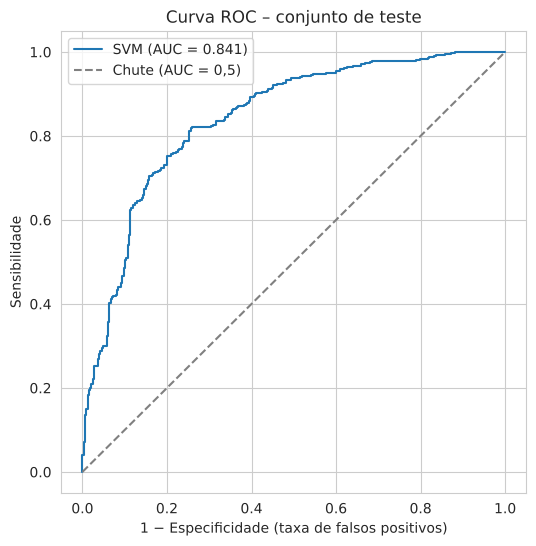

In [22]:
pontuacao = modelo_escolhido.decision_function(X_teste)   # "nota" do SVM para cada vinho
fpr, tpr, _ = roc_curve(y_teste, pontuacao)
auc = roc_auc_score(y_teste, pontuacao)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'{nome_escolhido} (AUC = {auc:.3f})')
plt.plot([0, 1], [0, 1], '--', color='gray', label='Chute (AUC = 0,5)')
plt.xlabel('1 − Especificidade (taxa de falsos positivos)')
plt.ylabel('Sensibilidade')
plt.title('Curva ROC – conjunto de teste')
plt.legend()
plt.show()

### 4.3 Interpretação para a vinícola
**Impacto prático dos erros**
- **Falso Positivo (FP) – vinho Regular aprovado como Bom:** é o erro **mais grave** para a marca. O vinho vai
  para o lote e o preço de vinho bom, o consumidor percebe a qualidade inferior → reclamação, devolução e
  desgaste da reputação.
- **Falso Negativo (FN) – vinho Bom rebaixado para Regular:** gera **perda de receita**, pois o vinho é vendido
  mais barato (ou volta para nova análise), mas não decepciona o cliente.

**Métricas** (valores do teste na tabela acima)
- **Acurácia (~79%):** cerca de 4 em cada 5 vinhos classificados corretamente, bem acima dos 66,5% do chute "sempre Bom".
- **Precisão (~82%):** quando o modelo aprova um vinho como Bom, acerta em cerca de 8 a cada 10 casos.
- **Sensibilidade (~87%):** reconhece a grande maioria dos vinhos bons.
- **Especificidade (~62%):** é o ponto fraco – quase 4 em cada 10 vinhos regulares passam como Bom
  (a classe Regular é minoria e se sobrepõe à classe Bom).
- **F1 (~85%):** bom equilíbrio entre precisão e sensibilidade.
- As métricas de teste ficaram muito perto das da validação cruzada → o modelo **não decorou o treino**.

**Uso recomendado:** como ferramenta de **triagem**. Vinhos classificados como "Regular" podem ser separados
com boa confiança; os classificados como "Bom" passam por uma degustação de confirmação. Para reduzir os
Falsos Positivos, dá para mudar o limite de decisão do SVM (andar na curva ROC) ou dar mais peso à classe
Regular no treino, trocando um pouco de sensibilidade por especificidade.

---
# Conclusão
O melhor modelo foi o **SVM com kernel RBF (C = 10)**: maior acurácia e maior F1 na validação cruzada dentro do
grupo de treino, e desempenho praticamente igual no teste. Ele venceu porque as classes se sobrepõem de forma
não linear (Fase 1) e o kernel RBF consegue traçar fronteiras curvas combinando os 11 atributos padronizados.
A Rede Neural MLP foi uma alternativa muito próxima; a Árvore ficou no meio; os lineares (Regressão Logística e
Perceptron) foram os piores. O limite principal é a especificidade (~62%), por isso o modelo serve melhor como
apoio à triagem do que como substituto da avaliação sensorial.